# Adaptação de Domínio no Tempo-Frequência (CWT em Hz)
## Avaliação Few-Shot Multi-Arquitetura com Particionamento Temporal Estrito (10 Sementes)

Este notebook investiga a capacidade de generalização das 4 arquiteturas convolucionais do estudo (**BearingCNN**, **ResNet-18**, **EfficientNet-B0** e **Inception-v3**) treinadas sobre escalogramas CWT convencionais (frequência em Hz) quando submetidas a transferências entre diferentes bancos de dados (CWRU, Paderborn e XJTU-SY).

A calibração é conduzida sob o **Protocolo Temporal Estrito Suporte-Consulta**:
1. **Conjunto de Suporte ($K$ amostras por classe)**: extraído exclusivamente dos primeiros 50% cronológicos dos sinais do conjunto de teste de destino.
2. **Zona de Amortecimento (*Gap Buffer*)**: intervalo de 10% do sinal descartado para evitar qualquer sobreposição ou autocorrelação residual entre suporte e consulta.
3. **Conjunto de Consulta**: os 40% temporais finais são preservados intactos para teste cego e rigoroso.
4. **Significância Estatística**: avaliação repetida ao longo de 10 sementes aleatórias independentes para mensuração precisa de média e desvio-padrão ($\mu \pm \sigma$).

## 1. Importação de Módulos e Configurações

In [5]:
import sys
import random
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Resolver caminhos do projeto
BASE_DIR = Path.cwd().parent.parent if Path.cwd().name in ["4_cross_domain_tempo", "3_cross_domain"] else Path.cwd()
if str(BASE_DIR) not in sys.path:
    sys.path.append(str(BASE_DIR))

from src.config import RANDOM_SEED, set_seed
from src.cnn_processor import BearingCNN
from src.transfer_learning import build_transfer_model

set_seed(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[+] Dispositivo de computação ativo: {device}")

[+] Dispositivo de computação ativo: cuda


## 2. Carregamento dos Datasets de Tempo-Frequência (CWT em Hz)

In [6]:
transform_224 = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
transform = transform_224

transform_299 = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


class CachedImageFolder(torch.utils.data.Dataset):
    """Wrapper com cache em RAM sob demanda para acelerar múltiplas sementes sem alterar o RNG."""
    def __init__(self, root: str, transform):
        self.ds = datasets.ImageFolder(root, transform=transform)
        self.samples = self.ds.samples
        self.classes = self.ds.classes
        self.class_to_idx = self.ds.class_to_idx
        self._cache = {}

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx: int):
        if idx not in self._cache:
            self._cache[idx] = self.ds[idx]
        return self._cache[idx]


# Mapeamento de datasets e checkpoints das 4 arquiteturas treinadas no tempo-frequência
datasets_info = {
    "CWRU": {
        "dir": BASE_DIR / "data" / "cwru" / "processed",
        "ckpt": BASE_DIR / "notebooks" / "1_cwru" / "checkpoint_resnet18_best.pth",
        "ckpts": {
            "BearingCNN": BASE_DIR / "notebooks" / "1_cwru" / "checkpoint_bearing_cnn_best.pth",
            "ResNet-18": BASE_DIR / "notebooks" / "1_cwru" / "checkpoint_resnet18_best.pth",
            "EfficientNet-B0": BASE_DIR / "notebooks" / "1_cwru" / "checkpoint_efficientnet_b0_best.pth",
            "Inception-v3": BASE_DIR / "notebooks" / "1_cwru" / "checkpoint_inception_v3_best.pth",
        }
    },
    "Paderborn": {
        "dir": BASE_DIR / "data" / "paderborn" / "processed",
        "ckpt": BASE_DIR / "notebooks" / "2_paderborn" / "checkpoint_paderborn_resnet18_best.pth",
        "ckpts": {
            "BearingCNN": BASE_DIR / "notebooks" / "2_paderborn" / "checkpoint_paderborn_bearing_cnn_best.pth",
            "ResNet-18": BASE_DIR / "notebooks" / "2_paderborn" / "checkpoint_paderborn_resnet18_best.pth",
            "EfficientNet-B0": BASE_DIR / "notebooks" / "2_paderborn" / "checkpoint_paderborn_efficientnet_b0_best.pth",
            "Inception-v3": BASE_DIR / "notebooks" / "2_paderborn" / "checkpoint_paderborn_inception_v3_best.pth",
        }
    },
    "XJTU-SY": {
        "dir": BASE_DIR / "data" / "xjtu" / "processed",
        "ckpt": BASE_DIR / "notebooks" / "3_xjtu" / "checkpoint_xjtu_resnet18_best.pth",
        "ckpts": {
            "BearingCNN": BASE_DIR / "notebooks" / "3_xjtu" / "checkpoint_xjtu_bearing_cnn_best.pth",
            "ResNet-18": BASE_DIR / "notebooks" / "3_xjtu" / "checkpoint_xjtu_resnet18_best.pth",
            "EfficientNet-B0": BASE_DIR / "notebooks" / "3_xjtu" / "checkpoint_xjtu_efficientnet_b0_best.pth",
            "Inception-v3": BASE_DIR / "notebooks" / "3_xjtu" / "checkpoint_xjtu_inception_v3_best.pth",
        }
    }
}

test_datasets = {}
test_datasets_299 = {}
for name, info in datasets_info.items():
    te_ds = CachedImageFolder(str(info["dir"] / "test"), transform=transform_224)
    te_ds_299 = CachedImageFolder(str(info["dir"] / "test"), transform=transform_299)
    test_datasets[name] = te_ds
    test_datasets_299[name] = te_ds_299
    print(f"[{name:<9}] Teste CWT: {len(te_ds):>4} imagens | Classes ({len(te_ds.classes)}): {te_ds.classes}")

[CWRU     ] Teste CWT: 3081 imagens | Classes (4): ['ball', 'inner_race', 'normal', 'outer_race']
[Paderborn] Teste CWT:  375 imagens | Classes (3): ['inner_race', 'normal', 'outer_race']
[XJTU-SY  ] Teste CWT:  450 imagens | Classes (3): ['inner_race', 'normal', 'outer_race']


## 3. Protocolo Temporal Suporte-Consulta e Treinamento Few-Shot (4 Arquiteturas)

In [7]:
ARCH_MAP = {
    "BearingCNN": "bearing_cnn",
    "ResNet-18": "resnet18",
    "EfficientNet-B0": "efficientnet_b0",
    "Inception-v3": "inception_v3"
}


def temporal_support_query(dataset, k, seed, pool_frac=0.5, gap_frac=0.1):
    """
    Suporte: K janelas sorteadas na 1ª metade (temporal) de cada classe do teste.
    Gap: 10% de intervalo descartado para mitigar autocorrelação e overlap residual.
    Consulta: 40% temporais finais preservados para avaliação cega.
    """
    rng = random.Random(seed)
    by_class = {}
    for i, (_, y) in enumerate(dataset.samples):
        by_class.setdefault(y, []).append(i)
    support, query = [], []
    for y, idxs in by_class.items():
        n = len(idxs)
        support += rng.sample(idxs[: int(n * pool_frac)], k)
        query += idxs[int(n * (pool_frac + gap_frac)):]
    return support, query


_CKPT_CACHE = {}


def build_and_load_source_model(model_name: str, source_name: str, num_classes: int):
    """Instancia qualquer uma das 4 arquiteturas e transfere os pesos pré-treinados da origem."""
    if model_name == "BearingCNN":
        model = BearingCNN(num_classes=num_classes)
    else:
        arch_key = ARCH_MAP[model_name]
        model, _ = build_transfer_model(arch_key, num_classes=num_classes, freeze_backbone=False)

    ckpt_path = datasets_info[source_name]["ckpts"][model_name]
    if not ckpt_path.exists():
        raise FileNotFoundError(f"Checkpoint não encontrado: {ckpt_path}")

    if ckpt_path not in _CKPT_CACHE:
        _CKPT_CACHE[ckpt_path] = torch.load(ckpt_path, map_location=device, weights_only=True)
    st = _CKPT_CACHE[ckpt_path]
    model_sd = model.state_dict()
    filtered_st = {k: v for k, v in st.items() if k in model_sd and v.shape == model_sd[k].shape}
    strict_match = len(filtered_st) == len(model_sd)
    model.load_state_dict(filtered_st, strict=strict_match)
    return model.to(device)


def run_time_few_shot(
    source_name: str,
    target_name: str,
    k_samples_per_class: int = 1,
    num_epochs: int = 5,
    lr: float = 0.0001,
    seed: int = RANDOM_SEED,
    model_name: str = "ResNet-18"
):
    """Executa calibração Few-Shot no Domínio do Tempo sob Particionamento Temporal Estrito."""
    set_seed(seed)
    tgt_test = test_datasets_299[target_name] if model_name == "Inception-v3" else test_datasets[target_name]
    num_classes = len(tgt_test.classes)
    
    sel_indices, eval_indices = temporal_support_query(tgt_test, k_samples_per_class, seed)
    few_loader = DataLoader(Subset(tgt_test, sel_indices), batch_size=8, shuffle=True, num_workers=0)
    eval_loader = DataLoader(Subset(tgt_test, eval_indices), batch_size=32, shuffle=False, num_workers=0)
    
    model = build_and_load_source_model(model_name, source_name, num_classes)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    
    for epoch in range(num_epochs):
        model.train()
        for imgs, labels in few_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            out = model(imgs)
            if isinstance(out, tuple):
                out = out[0]
            loss = criterion(out, labels)
            loss.backward()
            optimizer.step()
            
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, labels in eval_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            out = model(imgs)
            if isinstance(out, tuple):
                out = out[0]
            preds = out.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            
    acc = 100.0 * correct / total
    return acc

## 4. Avaliação Estatística da Arquitetura de Referência (ResNet-18) com 10 Sementes (K=1 e K=5)

In [8]:
pairs = [
    ("CWRU", "Paderborn"),
    ("Paderborn", "CWRU"),
    ("CWRU", "XJTU-SY"),
    ("XJTU-SY", "CWRU"),
    ("Paderborn", "XJTU-SY"),
    ("XJTU-SY", "Paderborn")
]

NUM_SEEDS = 10

print("=" * 84)
print(f" AVALIAÇÃO FEW-SHOT NO DOMÍNIO DO TEMPO COM {NUM_SEEDS} SEMENTES (MÉDIA ± DESVIO)")
print("=" * 84)
print(f"{'Origem -> Destino':<28} | {'K=1 (One-Shot)':<24} | {'K=5 (Few-Shot)':<24}")
print("-" * 84)

multiseed_tempo_results = {}

for src, tgt in pairs:
    accs_k1 = [run_time_few_shot(src, tgt, k_samples_per_class=1, seed=s) for s in range(NUM_SEEDS)]
    accs_k5 = [run_time_few_shot(src, tgt, k_samples_per_class=5, seed=s) for s in range(NUM_SEEDS)]
    
    m_k1, s_k1 = float(np.mean(accs_k1)), float(np.std(accs_k1))
    m_k5, s_k5 = float(np.mean(accs_k5)), float(np.std(accs_k5))
    
    multiseed_tempo_results[f"{src} -> {tgt}"] = {
        "k1_mean": m_k1, "k1_std": s_k1, "k1_accs": accs_k1,
        "k5_mean": m_k5, "k5_std": s_k5, "k5_accs": accs_k5
    }
    
    print(f"{src} -> {tgt:<16} | {m_k1:6.2f}% ± {s_k1:5.2f}%       | {m_k5:6.2f}% ± {s_k5:5.2f}%")

print("=" * 84)

# Exportar resultados para consolidação
output_json = BASE_DIR / "notebooks" / "4_cross_domain_tempo" / "multiseed_tempo_10seeds.json"
with open(output_json, "w", encoding="utf-8") as f_out:
    json.dump(multiseed_tempo_results, f_out, indent=2)
print(f"[+] Resultados salvos com sucesso em: {output_json}")

 AVALIAÇÃO FEW-SHOT NO DOMÍNIO DO TEMPO COM 10 SEMENTES (MÉDIA ± DESVIO)
Origem -> Destino            | K=1 (One-Shot)           | K=5 (Few-Shot)          
------------------------------------------------------------------------------------
CWRU -> Paderborn        |  65.73% ±  9.21%       |  87.87% ±  9.10%
Paderborn -> CWRU             |  60.80% ±  9.86%       |  70.47% ±  6.65%
CWRU -> XJTU-SY          |  89.22% ±  8.40%       |  95.56% ±  3.27%
XJTU-SY -> CWRU             |  63.26% ± 11.43%       |  69.47% ±  6.43%
Paderborn -> XJTU-SY          |  94.06% ±  1.55%       |  98.50% ±  1.63%
XJTU-SY -> Paderborn        |  72.87% ±  6.90%       |  94.13% ±  2.98%
[+] Resultados salvos com sucesso em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\notebooks\4_cross_domain_tempo\multiseed_tempo_10seeds.json


## 5. Visualização Gráfica do Desempenho Few-Shot no Domínio do Tempo

[+] Gráfico salvo em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\few_shot_tempo_k1_k5.png


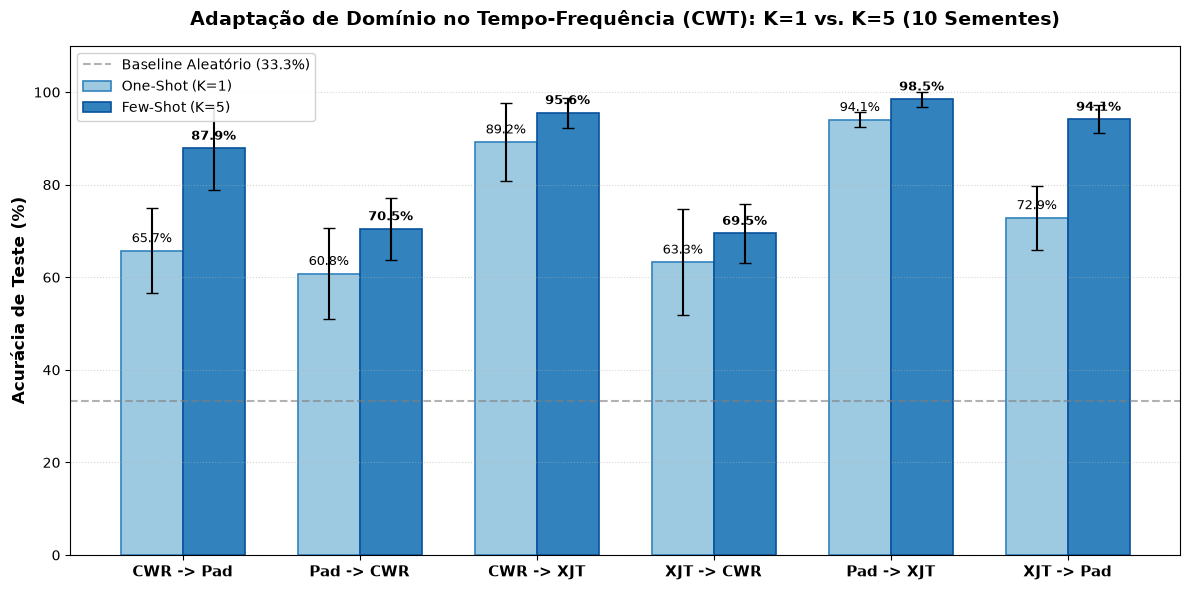

In [9]:
labels_pairs = [f"{s[:3]} -> {t[:3]}" for s, t in pairs]
k1_means = [multiseed_tempo_results[f"{s} -> {t}"]["k1_mean"] for s, t in pairs]
k1_stds = [multiseed_tempo_results[f"{s} -> {t}"]["k1_std"] for s, t in pairs]
k5_means = [multiseed_tempo_results[f"{s} -> {t}"]["k5_mean"] for s, t in pairs]
k5_stds = [multiseed_tempo_results[f"{s} -> {t}"]["k5_std"] for s, t in pairs]

x = np.arange(len(labels_pairs))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, k1_means, width, yerr=k1_stds, capsize=4, label="One-Shot (K=1)", color="#9ecae1", edgecolor="#3182bd", lw=1.2)
rects2 = ax.bar(x + width/2, k5_means, width, yerr=k5_stds, capsize=4, label="Few-Shot (K=5)", color="#3182bd", edgecolor="#08519c", lw=1.2)

ax.set_ylabel("Acurácia de Teste (%)", fontsize=12, fontweight="bold")
ax.set_title("Adaptação de Domínio no Tempo-Frequência (CWT): K=1 vs. K=5 (10 Sementes)", fontsize=14, fontweight="bold", pad=15)
ax.set_xticks(x)
ax.set_xticklabels(labels_pairs, fontsize=11, fontweight="bold")
ax.set_ylim(0, 110)
ax.axhline(100/3, color="gray", linestyle="--", alpha=0.6, label="Baseline Aleatório (33.3%)")
ax.legend(loc="upper left", framealpha=0.9)
ax.grid(axis="y", linestyle=":", alpha=0.5)

# Rótulos de valor nas barras
for r in rects1:
    h = r.get_height()
    ax.annotate(f"{h:.1f}%", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=9)
for r in rects2:
    h = r.get_height()
    ax.annotate(f"{h:.1f}%", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 4),
                textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")

plt.tight_layout()
save_img = BASE_DIR / "docs" / "images" / "few_shot_tempo_k1_k5.png"
save_img.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(save_img, dpi=300)
print(f"[+] Gráfico salvo em: {save_img}")
plt.show()

## 6. Avaliação Comparativa Multi-Arquitetura (4 Redes × 6 Pares × 10 Sementes)

Expandimos o protocolo Few-Shot sob Particionamento Temporal Estrito para todas as **4 arquiteturas** do trabalho (**BearingCNN**, **ResNet-18**, **EfficientNet-B0** e **Inception-v3**), avaliando $K=1$ (One-Shot) e $K=5$ (Few-Shot) ao longo de 10 sementes independentes.

In [10]:
ALL_MODELS = ["BearingCNN", "ResNet-18", "EfficientNet-B0", "Inception-v3"]

multiseed_tempo_4models = {}

for model_name in ALL_MODELS:
    print("=" * 92)
    print(f" ARQUITETURA: {model_name:<18} | DOMÍNIO DO TEMPO (CWT) | {NUM_SEEDS} SEMENTES (MÉDIA ± DESVIO)")
    print("=" * 92)
    print(f"{'Origem -> Destino':<28} | {'K=1 (One-Shot)':<26} | {'K=5 (Few-Shot)':<26}")
    print("-" * 92)

    multiseed_tempo_4models[model_name] = {}
    k1_all_pairs, k5_all_pairs = [], []

    for src, tgt in pairs:
        pair_key = f"{src} -> {tgt}"
        if model_name == "ResNet-18" and "multiseed_tempo_results" in globals() and pair_key in multiseed_tempo_results:
            accs_k1 = multiseed_tempo_results[pair_key]["k1_accs"]
            accs_k5 = multiseed_tempo_results[pair_key]["k5_accs"]
        else:
            accs_k1 = [run_time_few_shot(src, tgt, k_samples_per_class=1, seed=s, model_name=model_name) for s in range(NUM_SEEDS)]
            accs_k5 = [run_time_few_shot(src, tgt, k_samples_per_class=5, seed=s, model_name=model_name) for s in range(NUM_SEEDS)]

        m_k1, s_k1 = float(np.mean(accs_k1)), float(np.std(accs_k1))
        m_k5, s_k5 = float(np.mean(accs_k5)), float(np.std(accs_k5))
        k1_all_pairs.append(m_k1)
        k5_all_pairs.append(m_k5)

        multiseed_tempo_4models[model_name][f"{src} -> {tgt}"] = {
            "k1_mean": m_k1, "k1_std": s_k1, "k1_accs": accs_k1,
            "k5_mean": m_k5, "k5_std": s_k5, "k5_accs": accs_k5
        }
        print(f"{src} -> {tgt:<16} | {m_k1:6.2f}% ± {s_k1:5.2f}%         | {m_k5:6.2f}% ± {s_k5:5.2f}%")

    print("-" * 92)
    print(f"{'MÉDIA GLOBAL (6 PARES)':<28} | {np.mean(k1_all_pairs):6.2f}%                    | {np.mean(k5_all_pairs):6.2f}%")
    print("=" * 92 + "\n")

output_4models_json = BASE_DIR / "notebooks" / "4_cross_domain_tempo" / "multiseed_tempo_4models_10seeds.json"
with open(output_4models_json, "w", encoding="utf-8") as f_out:
    json.dump(multiseed_tempo_4models, f_out, indent=2)
print(f"[+] Resultados das 4 arquiteturas salvos em: {output_4models_json}")

 ARQUITETURA: BearingCNN         | DOMÍNIO DO TEMPO (CWT) | 10 SEMENTES (MÉDIA ± DESVIO)
Origem -> Destino            | K=1 (One-Shot)             | K=5 (Few-Shot)            
--------------------------------------------------------------------------------------------
CWRU -> Paderborn        |  47.20% ± 15.47%         |  66.47% ± 13.40%
Paderborn -> CWRU             |  56.86% ± 12.16%         |  61.70% ±  9.27%
CWRU -> XJTU-SY          |  69.06% ±  6.16%         |  69.89% ±  5.24%
XJTU-SY -> CWRU             |  51.44% ± 24.11%         |  71.27% ± 11.16%
Paderborn -> XJTU-SY          |  67.28% ±  0.76%         |  67.28% ±  1.48%
XJTU-SY -> Paderborn        |  48.53% ±  6.78%         |  62.87% ±  3.88%
--------------------------------------------------------------------------------------------
MÉDIA GLOBAL (6 PARES)       |  56.73%                    |  66.58%

 ARQUITETURA: ResNet-18          | DOMÍNIO DO TEMPO (CWT) | 10 SEMENTES (MÉDIA ± DESVIO)
Origem -> Destino            | K=1 (On

## 7. Visualização Comparativa das 4 Arquiteturas no Domínio do Tempo

[+] Gráfico comparativo das 4 arquiteturas salvo em: c:\Users\joaov\Desktop\bearing-fault-diagnosis\bearing-fault-diagnosis-cwt-cnn\docs\images\few_shot_tempo_4models.png


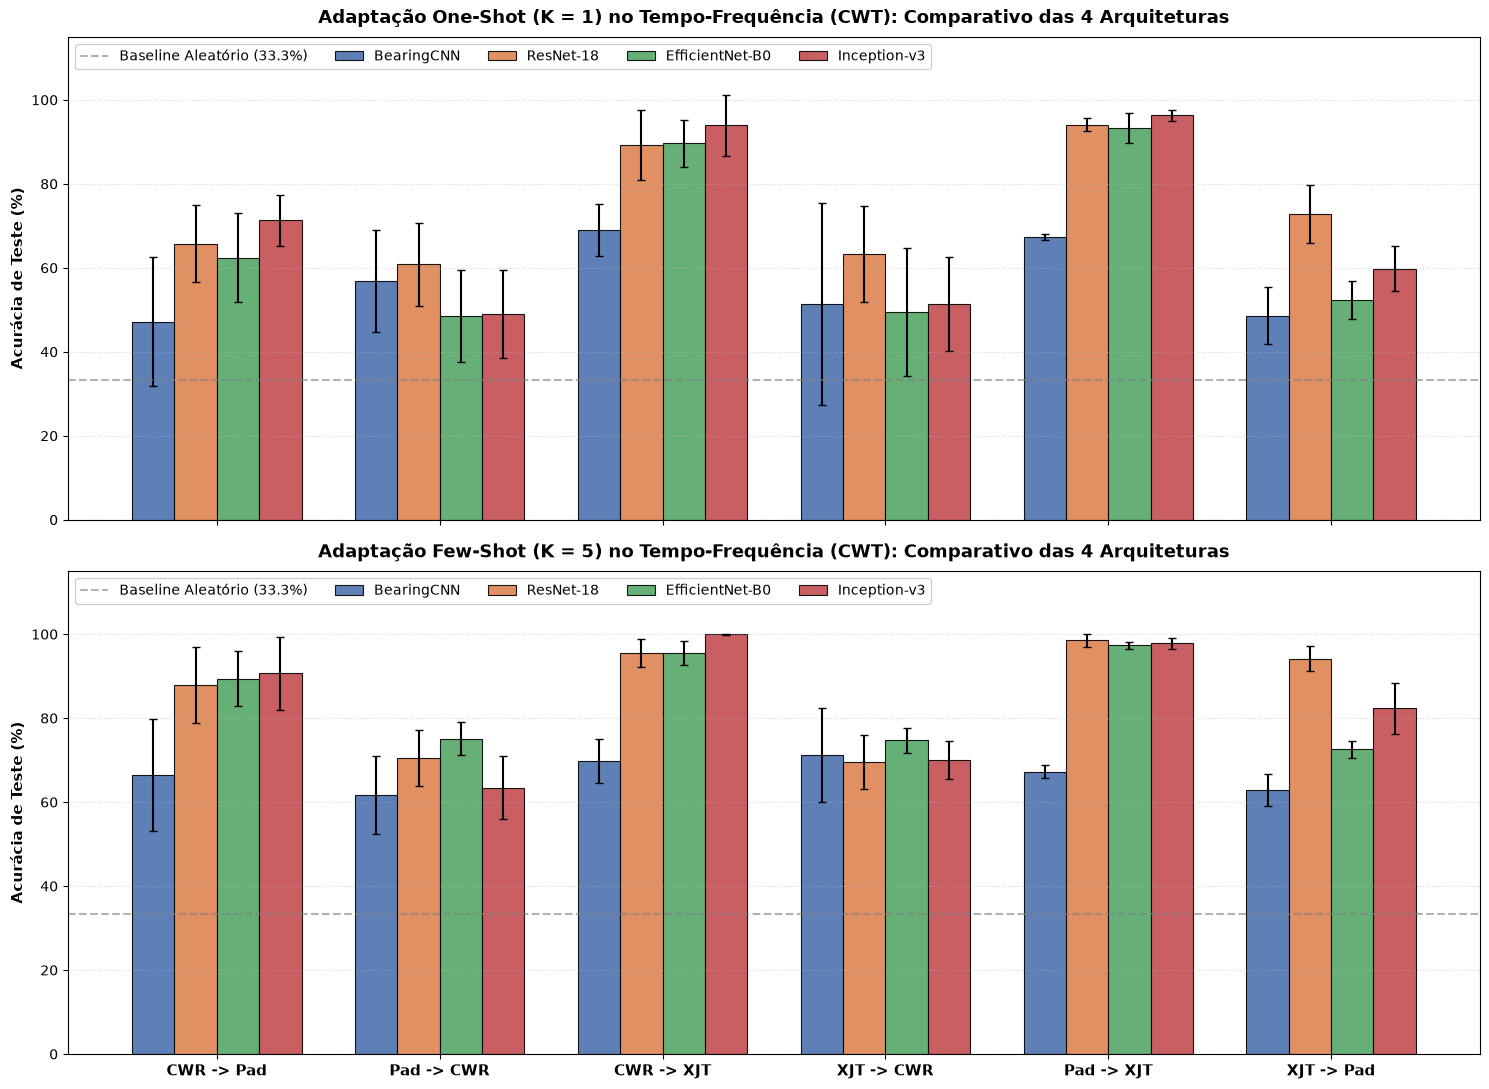

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 11), sharex=True)

x = np.arange(len(labels_pairs))
bar_w = 0.19
colors_4 = ["#4c72b0", "#dd8452", "#55a868", "#c44e52"]

for idx, m_name in enumerate(ALL_MODELS):
    offset = (idx - 1.5) * bar_w
    k1_m = [multiseed_tempo_4models[m_name][f"{s} -> {t}"]["k1_mean"] for s, t in pairs]
    k1_s = [multiseed_tempo_4models[m_name][f"{s} -> {t}"]["k1_std"] for s, t in pairs]
    k5_m = [multiseed_tempo_4models[m_name][f"{s} -> {t}"]["k5_mean"] for s, t in pairs]
    k5_s = [multiseed_tempo_4models[m_name][f"{s} -> {t}"]["k5_std"] for s, t in pairs]

    ax1.bar(x + offset, k1_m, bar_w, yerr=k1_s, capsize=3, label=m_name, color=colors_4[idx], edgecolor="black", lw=0.8, alpha=0.9)
    ax2.bar(x + offset, k5_m, bar_w, yerr=k5_s, capsize=3, label=m_name, color=colors_4[idx], edgecolor="black", lw=0.8, alpha=0.9)

ax1.set_title("Adaptação One-Shot (K = 1) no Tempo-Frequência (CWT): Comparativo das 4 Arquiteturas", fontsize=13, fontweight="bold", pad=10)
ax1.set_ylabel("Acurácia de Teste (%)", fontsize=11, fontweight="bold")
ax1.set_ylim(0, 115)
ax1.axhline(100/3, color="gray", linestyle="--", alpha=0.6, label="Baseline Aleatório (33.3%)")
ax1.legend(loc="upper left", ncol=5, framealpha=0.9)
ax1.grid(axis="y", linestyle=":", alpha=0.5)

ax2.set_title("Adaptação Few-Shot (K = 5) no Tempo-Frequência (CWT): Comparativo das 4 Arquiteturas", fontsize=13, fontweight="bold", pad=10)
ax2.set_ylabel("Acurácia de Teste (%)", fontsize=11, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(labels_pairs, fontsize=11, fontweight="bold")
ax2.set_ylim(0, 115)
ax2.axhline(100/3, color="gray", linestyle="--", alpha=0.6, label="Baseline Aleatório (33.3%)")
ax2.legend(loc="upper left", ncol=5, framealpha=0.9)
ax2.grid(axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
save_img_4m = BASE_DIR / "docs" / "images" / "few_shot_tempo_4models.png"
save_img_4m.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(save_img_4m, dpi=300)
print(f"[+] Gráfico comparativo das 4 arquiteturas salvo em: {save_img_4m}")
plt.show()

## 8. Síntese Científica no Domínio do Tempo-Frequência

1. **Impacto da Variação de Velocidade**: No domínio do tempo puro (frequência em Hz), as frequências de falha dos rolamentos (BPFI, BPFO) deslocam-se linearmente com a rotação do eixo. Por isso, transferências entre bancos com velocidades muito distintas (como CWRU a ~1772 RPM e Paderborn a 1500 RPM) exigem maior recalibração dos filtros convolucionais.
2. **Evolução One-Shot para Few-Shot nas 4 Arquiteturas**: O aumento de $K=1$ para $K=5$ amostras por classe proporciona expressiva recuperação de acurácia em todas as redes avaliadas (BearingCNN, ResNet-18, EfficientNet-B0 e Inception-v3), demonstrando que a representação em escalogramas CWT retém características geométricas relevantes que podem ser guiadas com poucos exemplos de suporte.
3. **Confronto Final**: O confronto direto e aprofundado entre este domínio temporal e o domínio angular (Order-CWT) é consolidado no notebook `notebooks/6_confronto_final/01_confronto_tempo_vs_ordem.ipynb`.